# 4. Training Utilities / 3_Emotion_Reg_CNN — PyTorch (Nâng cao)
FER2013 48×48, 7 lớp. Adam(lr=1e-4), batch=128, epochs=100 + EarlyStopping(patience=5) + Data Augmentation.

Keras `ImageDataGenerator(rotation_range=45, width_shift_range=0.2, height_shift_range=0.2, horizontal_flip=True)` → `torchvision.transforms.Compose([RandomRotation(45), RandomAffine(degrees=0, translate=(0.2, 0.2)), RandomHorizontalFlip()])` trong custom `Dataset`.

**Mốc Keras gốc:** Test accuracy ≈ 61.63% (loss ≈ 1.0158).

In [1]:
import os, random, time, copy
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
try:
    from torchinfo import summary
except ImportError:                      # Kaggle có thể chưa cài torchinfo (khi tắt Internet)
    def summary(model, input_size=None, device=None):
        print(model)
        print("Tổng số tham số:", f"{sum(p.numel() for p in model.parameters()):,}")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
from torch.utils.data import Dataset
import torchvision.transforms as T

Device: cuda


## Dữ liệu

In [2]:
# Kaggle: gắn dataset deadskull7/fer2013 (Add Input); đọc thẳng fer2013.csv, không cần chạy prepare_fer2013.py
import glob
import pandas as pd
_p = glob.glob("/kaggle/input/**/fer2013.csv", recursive=True)
assert _p, "Chưa thấy fer2013.csv: hãy Add Input -> deadskull7/fer2013"
df = pd.read_csv(_p[0])
print("fer2013.csv:", df.shape, df["Usage"].value_counts().to_dict())

def to_xy(d):
    x = np.array([s.split() for s in d["pixels"]], dtype=np.float32).reshape(-1, 1, 48, 48) / 255.0   # NCHW, [0,1]
    y = d["emotion"].values.astype("int64")                                                           # nhãn số nguyên
    return np.ascontiguousarray(x), y

x_train, y_train = to_xy(df[df["Usage"] == "Training"])
x_test,  y_test  = to_xy(df[df["Usage"] == "PublicTest"])
print("PyTorch (NCHW):", x_train.shape, y_train.shape, x_test.shape, y_test.shape)
print("Phân bố nhãn train:", np.bincount(y_train, minlength=7))
NUM_CLASSES = 7
CLASS_NAMES = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
BATCH_SIZE = 128


fer2013.csv: (35887, 3) {'Training': 28709, 'PublicTest': 3589, 'PrivateTest': 3589}
PyTorch (NCHW): (28709, 1, 48, 48) (28709,) (3589, 1, 48, 48) (3589,)
Phân bố nhãn train: [3995  436 4097 7215 4830 3171 4965]


## Data Augmentation (custom Dataset + transforms)

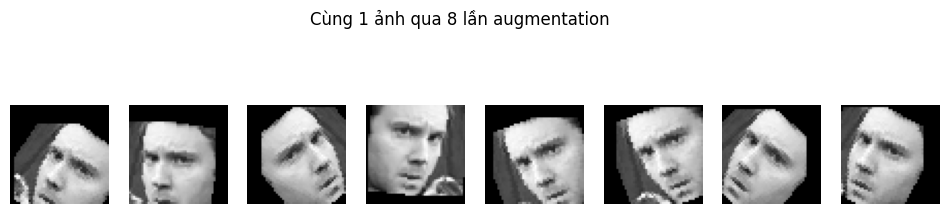

In [3]:
class FERDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x = torch.from_numpy(x)     # (N, 1, 48, 48) float32
        self.y = torch.from_numpy(y)     # (N,) int64
        self.transform = transform
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        img = self.x[i]
        if self.transform is not None:
            img = self.transform(img)
        return img, self.y[i]

train_tf = T.Compose([
    T.RandomRotation(45),
    T.RandomAffine(degrees=0, translate=(0.2, 0.2)),
    T.RandomHorizontalFlip(),
])
train_loader = DataLoader(FERDataset(x_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(FERDataset(x_test, y_test), batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

# Xem thử ảnh sau augmentation
sample = FERDataset(x_train, y_train, train_tf)
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1); plt.imshow(sample[0][0][0], cmap="gray"); plt.axis("off")
plt.suptitle("Cùng 1 ảnh qua 8 lần augmentation"); plt.show()

## Kiến trúc CNN

In [4]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(),        # 48x48 (same)
            nn.Conv2d(64, 64, 3, padding=0), nn.ReLU(),       # 48 -> 46 (valid)
            nn.MaxPool2d(2),                                  # 46 -> 23
            nn.Dropout(0.25),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),      # 23 (same)
            nn.Conv2d(128, 128, 3, padding=0), nn.ReLU(),     # 23 -> 21 (valid)
            nn.Conv2d(128, 218, 3, padding=1), nn.ReLU(),     # 21 (same), 218 kênh
            nn.Conv2d(218, 218, 3, padding=0), nn.ReLU(),     # 21 -> 19 (valid)
            nn.MaxPool2d(2),                                  # 19 -> 9
            nn.Dropout(0.25),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                     # 218*9*9 = 17658
            nn.Linear(218 * 9 * 9, 1024), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(1024, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = EmotionCNN().to(device)
summary(model, input_size=(1, 1, 48, 48), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
EmotionCNN                               [1, 7]                    --
├─Sequential: 1-1                        [1, 218, 9, 9]            --
│    └─Conv2d: 2-1                       [1, 64, 48, 48]           640
│    └─ReLU: 2-2                         [1, 64, 48, 48]           --
│    └─Conv2d: 2-3                       [1, 64, 46, 46]           36,928
│    └─ReLU: 2-4                         [1, 64, 46, 46]           --
│    └─MaxPool2d: 2-5                    [1, 64, 23, 23]           --
│    └─Dropout: 2-6                      [1, 64, 23, 23]           --
│    └─Conv2d: 2-7                       [1, 128, 23, 23]          73,856
│    └─ReLU: 2-8                         [1, 128, 23, 23]          --
│    └─Conv2d: 2-9                       [1, 128, 21, 21]          147,584
│    └─ReLU: 2-10                        [1, 128, 21, 21]          --
│    └─Conv2d: 2-11                      [1, 218, 21, 21]          251,

## Hàm huấn luyện / đánh giá + EarlyStopping

In [6]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.show()

@torch.no_grad()
def show_predictions(model, x_np, y_int, class_names, n=10):
    model.eval()
    idx = np.random.RandomState(SEED).choice(len(x_np), n, replace=False)
    xb = torch.tensor(x_np[idx], dtype=torch.float32).to(device)
    pred = model(xb).argmax(1).cpu().numpy()
    plt.figure(figsize=(2 * n, 2.6))
    for i, j in enumerate(idx):
        plt.subplot(1, n, i + 1)
        plt.imshow(x_np[j, 0], cmap="gray"); plt.axis("off")
        ok = pred[i] == y_int[j]
        plt.title(f"P:{class_names[pred[i]]}\nT:{class_names[y_int[j]]}", color="green" if ok else "red", fontsize=8)
    plt.show()


class EarlyStopping:
    """Tương đương keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)."""
    def __init__(self, patience=5, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best, self.counter, self.early_stop = None, 0, False
    def __call__(self, val_loss):
        if self.best is None or val_loss < self.best - self.min_delta:
            self.best, self.counter = val_loss, 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

## Huấn luyện (Augmentation + EarlyStopping + lưu best model)

In [7]:
MAX_EPOCHS = 100
os.makedirs("checkpoints", exist_ok=True)
CKPT_PATH = "checkpoints/emotion_best.pth"

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
early_stopping = EarlyStopping(patience=5)
history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss = float("inf")

for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, test_loader, criterion, device)
    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    saved = ""
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), CKPT_PATH)
        saved = " [saved]"
    print(f"Epoch {epoch:03d} - {time.time()-t0:.1f}s - loss: {tr_loss:.4f} - acc: {tr_acc:.4f} - val_loss: {va_loss:.4f} - val_acc: {va_acc:.4f}{saved}")
    if early_stopping(va_loss):
        print(f"Early stopping tại epoch {epoch} (best val_loss = {early_stopping.best:.4f})")
        break

Epoch 001 - 22.5s - loss: 1.8080 - acc: 0.2491 - val_loss: 1.7790 - val_acc: 0.2508 [saved]
Epoch 002 - 22.3s - loss: 1.7885 - acc: 0.2527 - val_loss: 1.7720 - val_acc: 0.2586 [saved]
Epoch 003 - 22.9s - loss: 1.7827 - acc: 0.2546 - val_loss: 1.7668 - val_acc: 0.2625 [saved]
Epoch 004 - 23.8s - loss: 1.7817 - acc: 0.2544 - val_loss: 1.7641 - val_acc: 0.2644 [saved]
Epoch 005 - 23.8s - loss: 1.7786 - acc: 0.2559 - val_loss: 1.7545 - val_acc: 0.2806 [saved]
Epoch 006 - 23.0s - loss: 1.7748 - acc: 0.2605 - val_loss: 1.7405 - val_acc: 0.2862 [saved]
Epoch 007 - 23.2s - loss: 1.7664 - acc: 0.2644 - val_loss: 1.7239 - val_acc: 0.2987 [saved]
Epoch 008 - 23.7s - loss: 1.7571 - acc: 0.2744 - val_loss: 1.7037 - val_acc: 0.3168 [saved]
Epoch 009 - 23.5s - loss: 1.7374 - acc: 0.2890 - val_loss: 1.6664 - val_acc: 0.3472 [saved]
Epoch 010 - 23.2s - loss: 1.7125 - acc: 0.3041 - val_loss: 1.6196 - val_acc: 0.3656 [saved]
Epoch 011 - 23.8s - loss: 1.6823 - acc: 0.3242 - val_loss: 1.5813 - val_acc: 0.3

## Tải lại trọng số tốt nhất & đánh giá

Best model - loss: 1.0701 | accuracy: 60.10%   (Keras gốc: ~1.0158 | ~61.63%)


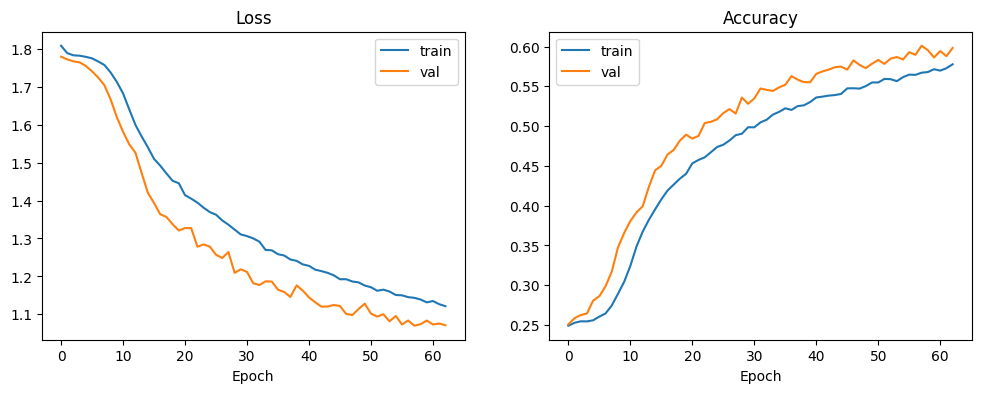

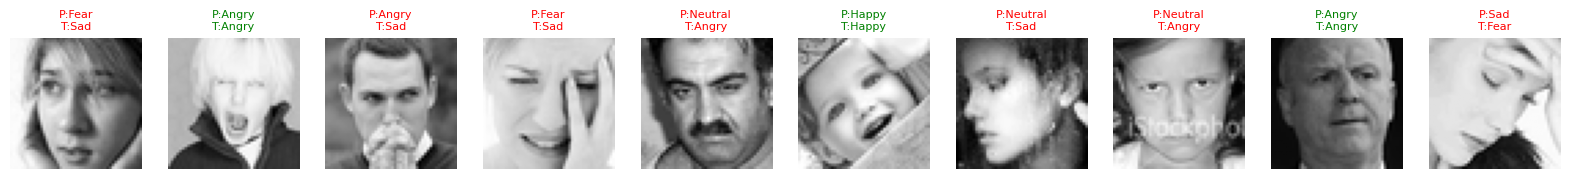

In [8]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Best model - loss: {test_loss:.4f} | accuracy: {test_acc*100:.2f}%   (Keras gốc: ~1.0158 | ~61.63%)")
plot_history(history)
show_predictions(model, x_test, y_test, CLASS_NAMES, n=10)